In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 8
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


In [2]:
for x, y in zip(Xtr[:20], Ytr[:20]):
    print(''.join(itos[ix.item()] for ix in x), '--->', itos[y.item()])

........ ---> y
.......y ---> u
......yu ---> h
.....yuh ---> e
....yuhe ---> n
...yuhen ---> g
..yuheng ---> .
........ ---> d
.......d ---> i
......di ---> o
.....dio ---> n
....dion ---> d
...diond ---> r
..diondr ---> e
.diondre ---> .
........ ---> x
.......x ---> a
......xa ---> v
.....xav ---> i
....xavi ---> e


In [3]:
from l5_classes import Linear, BatchNorm1d, Tanh, Embedding, FlattenConsecutive, Sequential

In [4]:
torch.manual_seed(42) # the generator inside py document is discarded

In [ ]:
n_embd = 24
n_hidden = 128

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

# parameter init
with torch.no_grad():
    model.layers[-1].weight *= 0.1 # last layer made less confident

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

76579


In [13]:
ix = torch.randint(0, Xtr.shape[0], (4,))
Xb, Yb = Xtr[ix], Ytr[ix]
logits = model(Xb)
print(Xb.shape)
Xb
for layer in model.layers:
    print(layer.__class__.__name__, ":", tuple(layer.out.shape))

torch.Size([4, 8])
Embedding : (4, 8, 24)
FlattenConsecutive : (4, 4, 48)
Linear : (4, 4, 128)
BatchNorm1d : (4, 4, 128)
Tanh : (4, 4, 128)
FlattenConsecutive : (4, 2, 256)
Linear : (4, 2, 128)
BatchNorm1d : (4, 2, 128)
Tanh : (4, 2, 128)
FlattenConsecutive : (4, 256)
Linear : (4, 128)
BatchNorm1d : (4, 128)
Tanh : (4, 128)
Linear : (4, 27)


In [14]:
model.layers[3].running_mean.shape

torch.Size([1, 1, 128])

In [15]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # changed 100000 to 150000 since it seems to need more time to converge
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

      0/ 200000: 3.2939
  10000/ 200000: 2.1695
  20000/ 200000: 1.9518
  30000/ 200000: 2.0320
  40000/ 200000: 1.8933
  50000/ 200000: 2.1787
  60000/ 200000: 1.8046
  70000/ 200000: 1.7574
  80000/ 200000: 1.8585
  90000/ 200000: 1.8076
 100000/ 200000: 1.7021
 110000/ 200000: 1.7005
 120000/ 200000: 1.8290
 130000/ 200000: 1.7612
 140000/ 200000: 2.0116
 150000/ 200000: 1.8499
 160000/ 200000: 2.2375
 170000/ 200000: 2.0721
 180000/ 200000: 1.8032
 190000/ 200000: 1.7951


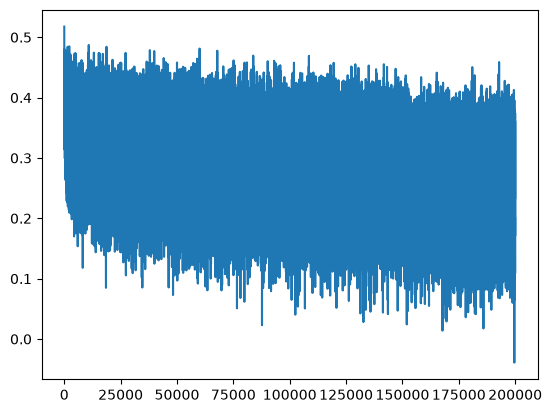

In [16]:
plt.plot(lossi)

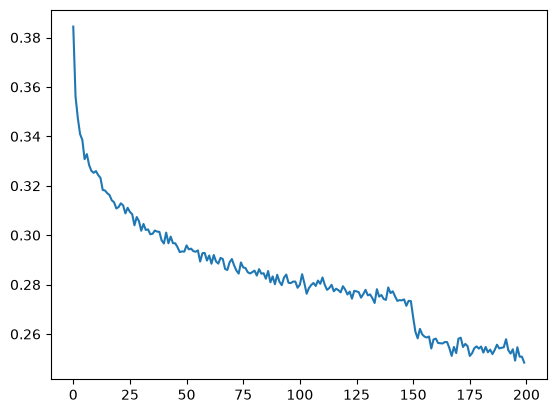

In [18]:
# change 1
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [19]:
# put layers into eval mode (it is needed for batchnorm layer especially, 
# which is some very unefficient and dangerous)
for layer in model.layers:
    layer.training = False

# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

print('----------------------')
print(split_loss('train'))
print(split_loss('val'))
print('----------------------\n')

# sample from the model
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))


----------------------
train 1.7667804956436157
None
val 1.9927217960357666
None
----------------------

karowan.
magdaley.
axtyn.
jaleina.
vashawn.
kaelani.
elona.
jazari.
ziya.
roxanna.
nariella.
lavey.
alechia.
gareth.
alehara.
aubriea.
malayah.
lawson.
keylani.
kynleigh.


* make the plot of lossi smoother
* create more kinds of layers in py
* pytorch.container: sequential
* RNN, n_hidden = 68
* fix batchNorm
* Increase n_embd -> 24, n_hidden -> 128